# KXINX vs. SPXW: option-implied probability

For a KXINX S&P-500-range event, compute each bucket's probability implied by real-time SPXW 0DTE option
quotes, and compare it to Kalshi's own bid/ask.

**Method: model-free (Breeden-Litzenberger), not Black-76.** `P(S_T > K) = -dC/dK` -- the (negative) slope
of the call-price-vs-strike curve at strike K, equivalently `1 - dP/dK` from puts -- estimated as a discrete
finite difference between the two listed strikes adjacent to K. This has **no volatility and no
time-to-expiry anywhere**: earlier attempts to do this via Black-76 (solve an implied vol, then price a
digital off it) implicitly assumed variance accrues at a constant rate through calendar time, which isn't
true intraday (well-documented U-shaped realized-vol pattern: higher near the open/close, lower at midday) --
correcting that properly would need a tedious, error-prone intraday variance-clock calibration. The
finite-difference approach sidesteps the whole problem: whatever the true variance clock is, it's already
embedded directly in the market's *relative* pricing across strikes at each instant, so there's nothing to
model or assume. A range bucket's probability is `P(S_T > floor) - P(S_T > cap)`.

All data is read from local caches only (`kalshi_infra/databento_functions.py` for SPXW,
`predexon_functions.py` for Kalshi) -- see `kalshi_latency_arbs/latency_arbs_functions.py` and `pricing.py`
for the actual computation.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("."))
sys.path.insert(0, os.path.abspath(os.path.join("..", "kalshi_infra")))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import latency_arbs_functions as laf

pd.set_option("display.max_columns", 20)


## Load one event and compute probabilities

`build_mids` also tracks each strike's bid-ask spread alongside its mid. `hold_through_wide_spread` uses
that to detect momentary liquidity pulls -- confirmed directly (raw orderbook inspection) that a handful of
strikes briefly go extremely wide, for anywhere from tens of milliseconds to a couple of seconds, as every
market maker momentarily pulls their quote -- and holds the *last normal-spread* mid (and spread) through
those windows instead of feeding a spurious, wide-spread mid into the finite difference. It also doesn't
release the hold the instant the spread first looks normal again -- it requires `settle_window` (300ms,
tuned as the shortest value that works) of *continuously* normal spread first, confirmed directly needed for
a case where a multi-second pull passed through one ~260ms window, mid-recovery, that briefly looked normal
before blowing back out again.

That fixes momentary noise on strikes that are otherwise liquid. It doesn't fix strikes that are just
*inherently* too illiquid for a tight estimate -- confirmed directly there's no single spread-widening
threshold that catches this, because nothing ever looks anomalous on either individual leg: a deep-ITM put
worth $150+ can have perfectly ordinary-looking bid-ask noise that's still large in *absolute* dollar terms,
which a small strike-gap finite difference is sensitive to regardless. `bucket_probabilities_ci` computes a
genuine confidence band directly from each moment's own bid/ask (no separate anomaly model at all -- a wide
band *is* the "not confident" signal), and `filter_confident_buckets` uses each bucket's typical band width
to decide whether it's worth analyzing at all, instead of chasing every deep bucket's own failure mode one
at a time.

In [ ]:
event_ticker = "KXINX-26AUG14H1600"
data = laf.load_event(event_ticker)

grid = laf._grid(data["session_start"], data["expiry"], freq="200ms")
defs = laf.dbf.get_option_definitions("SPXW", data["expiry"].date())

mids, spreads = laf.build_mids(data["spxw_quotes"], grid)
mids_held, spreads_held = laf.hold_through_wide_spread(mids, spreads, baseline_window="3min", multiplier=3.0, settle_window="300ms")

call_mid, put_mid = laf.build_price_curves(data["spxw_quotes"], mids_held, defs, grid)
call_spread, put_spread = laf.build_price_curves(data["spxw_quotes"], spreads_held, defs, grid)
probs_lo, probs, probs_hi = laf.bucket_probabilities_ci(data["markets"], call_mid, call_spread, put_mid, put_spread, grid)
kalshi_fair = laf.kalshi_fair_series(data["kalshi_ticks"], grid)

print(f"SPXW quote ticks: {len(data['spxw_quotes']):,} ({data['spxw_quotes']['raw_symbol'].nunique()} contracts)")
print(f"grid: {len(grid)} points, {grid[0]} -> {grid[-1]}")
print(f"probs: {probs.shape}")


## Which buckets are we actually confident in?

Median confidence-band width per bucket, restricted to the same live-session window (excludes the first 5
minutes after open and the last 45 minutes before close -- thin price discovery, and T->0 sensitivity for
the buckets that still use it, respectively) everything else below uses. `max_median_width=0.10` was picked
by inspecting the full ranking: it's naturally a clean cut -- the buckets right above it are exactly the two
we independently found and root-caused as unreliable (one from a still-present, un-fixed noise source; one
from genuine deep-ITM/OTM illiquidity), and every bucket below it visibly clusters tighter.

In [3]:
cutoff_open = data["session_start"] + pd.Timedelta("5min")
cutoff_close = data["expiry"] - pd.Timedelta("45min")
keep_idx = (grid >= cutoff_open) & (grid <= cutoff_close)

median_width = (probs_hi - probs_lo)[keep_idx].median().sort_values()
print("median confidence-band width, all buckets:")
print(median_width.to_string())

confident_tickers = laf.filter_confident_buckets(probs_lo, probs_hi, max_median_width=0.10, keep_idx=keep_idx)
print(f"\n{len(confident_tickers)}/{probs.shape[1]} buckets confident enough to analyze: {confident_tickers}")


median confidence-band width, all buckets:
KXINX-26AUG14H1600-B7787         0.0500
KXINX-26AUG14H1600-T8049.9999    0.0600
KXINX-26AUG14H1600-B7762         0.0625
KXINX-26AUG14H1600-B7812         0.0725
KXINX-26AUG14H1600-B7837         0.0800
KXINX-26AUG14H1600-B7737         0.0800
KXINX-26AUG14H1600-B7712         0.0850
KXINX-26AUG14H1600-B7862         0.0875
KXINX-26AUG14H1600-B7887         0.1075
KXINX-26AUG14H1600-B7687         0.1075
KXINX-26AUG14H1600-T7350         0.1200
KXINX-26AUG14H1600-B7912         0.1300
KXINX-26AUG14H1600-B7662         0.1300
KXINX-26AUG14H1600-B7637         0.1350
KXINX-26AUG14H1600-B7612         0.1350
KXINX-26AUG14H1600-B7587         0.1350
KXINX-26AUG14H1600-B7562         0.1400
KXINX-26AUG14H1600-B7937         0.1400
KXINX-26AUG14H1600-B7987         0.1700
KXINX-26AUG14H1600-B8012         0.1800
KXINX-26AUG14H1600-B8037         0.1800
KXINX-26AUG14H1600-B7537         0.1800
KXINX-26AUG14H1600-B7962         0.1975
KXINX-26AUG14H1600-B7512         0.22

## Option-implied probability vs. Kalshi's own price

The confident bucket with the largest average option-implied probability (closest to the money for most of
the session), shown with its confidence band.

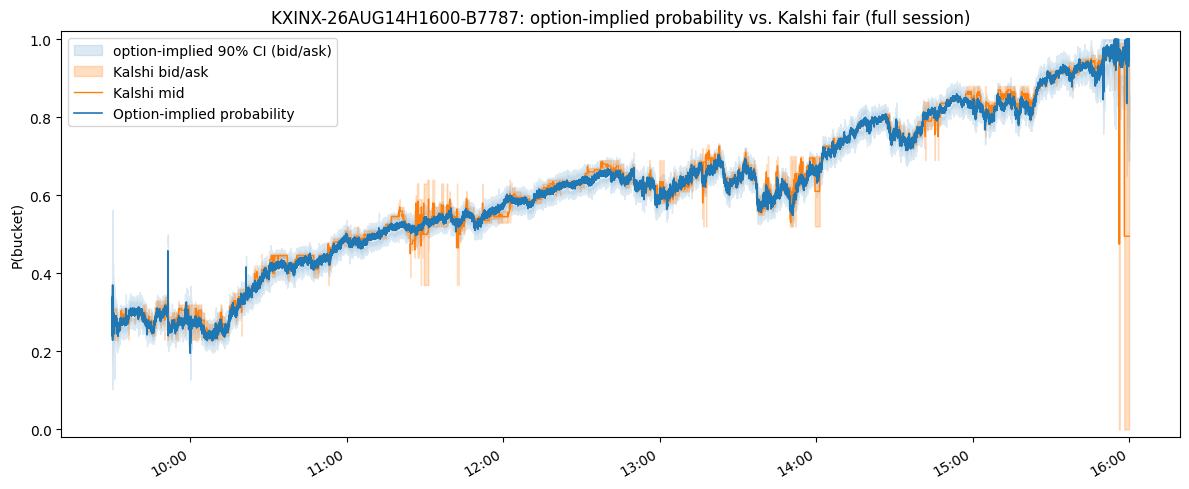

option-implied vs Kalshi mid, KXINX-26AUG14H1600-B7787: mean diff=-0.004, std=0.038, corr=0.980


In [4]:
atm_ticker = probs[confident_tickers].mean().idxmax()
kf = kalshi_fair[atm_ticker]

fig, ax = plt.subplots(figsize=(12, 5))
ax.fill_between(probs.index, probs_lo[atm_ticker], probs_hi[atm_ticker], color="tab:blue", alpha=0.15, label="option-implied 90% CI (bid/ask)")
ax.fill_between(kf.index, kf["bid"], kf["ask"], step="post", color="tab:orange", alpha=0.25, label="Kalshi bid/ask")
ax.plot(kf.index, kf["mid"], color="tab:orange", lw=1, label="Kalshi mid")
ax.plot(probs.index, probs[atm_ticker], color="tab:blue", lw=1.2, label="Option-implied probability")
ax.set_title(f"{atm_ticker}: option-implied probability vs. Kalshi fair (full session)")
ax.set_ylabel("P(bucket)")
ax.set_ylim(-0.02, 1.02)
ax.legend(loc="upper left")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=laf.ET))
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

diff = (probs[atm_ticker] - kf["mid"]).dropna()
print(f"option-implied vs Kalshi mid, {atm_ticker}: mean diff={diff.mean():+.3f}, std={diff.std():.3f}, "
      f"corr={probs[atm_ticker].corr(kf['mid']):.3f}")


## Where does the option-implied probability disagree most with Kalshi's own market?

Per *confident* bucket (from the filter above -- not a Kalshi-tick-count proxy anymore), its own top 3
moments where the option-implied probability sits furthest outside Kalshi's own quoted `[bid, ask]` band
(`find_worst_fit_moments`, called once per ticker) -- not one pooled top-10 across all buckets, so a
quieter bucket's own worst moments aren't crowded out by a louder one's. At most one per 15-minute window
per bucket. Excludes the first 5 minutes after open and the last 10 minutes before close, same reasoning as
the confidence-band window above.

Three additional guards, each confirmed directly to matter on real cases:
- `max_ci_width=0.08` -- *our own* confidence band has to be reasonably tight at that specific instant, not
  just that the bucket is confident on average (a severe, sustained, genuinely market-wide liquidity event
  can still pass through one normally-reliable bucket's `settle_window`, and chasing that with an
  ever-longer hold trades away real responsiveness elsewhere for no benefit).
- `sustain_window="1s"` -- ranks a centered rolling-median-smoothed distance, not the raw instantaneous one,
  so an isolated single-sample flicker can't win just by being a one-off outlier -- confirmed directly the
  candidates that survive the CI-width guard above are *already* genuinely sustained (the ranking barely
  moves between no smoothing and a 2s window), which is itself evidence these are real, not noise.
- A bucket can legitimately return fewer than 3 (even 0) -- that just means it tracked Kalshi well enough,
  within its own confidence band, for the whole session.

In [5]:
worst_fits = []
for ticker in confident_tickers:
    per_ticker = laf.find_worst_fit_moments(
        probs, kalshi_fair, tickers=[ticker], n=3,
        session_start=data["session_start"], exclude_after_open="5min",
        expiry=data["expiry"], exclude_before_expiry="10min",
        probs_lo=probs_lo, probs_hi=probs_hi, max_ci_width=0.08,
        sustain_window="1s",
    )
    print(f"{ticker} ({len(per_ticker)} qualifying moments):")
    for w in per_ticker:
        side = "above ask" if w["distance"] > 0 else "below bid"
        print(f"  {w['time']}  prob={w['prob']:.3f}  "
              f"kalshi=[{w['kalshi_bid']:.3f}, {w['kalshi_ask']:.3f}]  distance={w['distance']:+.3f} ({side})")
    worst_fits.extend(per_ticker)
print(f"\n{len(worst_fits)} total plots below")


KXINX-26AUG14H1600-B7737 (3 qualifying moments):
  2026-08-14 15:26:32+00:00  prob=0.058  kalshi=[0.010, 0.030]  distance=+0.028 (above ask)
  2026-08-14 15:42:58+00:00  prob=0.055  kalshi=[0.020, 0.040]  distance=+0.015 (above ask)
  2026-08-14 13:41:40.600000+00:00  prob=0.000  kalshi=[0.010, 0.050]  distance=-0.010 (below bid)
KXINX-26AUG14H1600-B7862 (3 qualifying moments):
  2026-08-14 13:37:50.200000+00:00  prob=0.000  kalshi=[0.030, 0.050]  distance=-0.030 (below bid)
  2026-08-14 14:08:34.800000+00:00  prob=0.008  kalshi=[0.030, 0.050]  distance=-0.022 (below bid)
  2026-08-14 14:25:05.200000+00:00  prob=0.000  kalshi=[0.020, 0.040]  distance=-0.020 (below bid)


KXINX-26AUG14H1600-T8049.9999 (2 qualifying moments):
  2026-08-14 16:58:50.200000+00:00  prob=0.015  kalshi=[0.000, 0.010]  distance=+0.005 (above ask)
  2026-08-14 13:50:58.200000+00:00  prob=0.013  kalshi=[0.000, 0.010]  distance=+0.003 (above ask)


KXINX-26AUG14H1600-B7712 (0 qualifying moments):


KXINX-26AUG14H1600-B7787 (3 qualifying moments):
  2026-08-14 15:26:37+00:00  prob=0.500  kalshi=[0.560, 0.600]  distance=-0.057 (below bid)
  2026-08-14 17:54:13.600000+00:00  prob=0.639  kalshi=[0.690, 0.700]  distance=-0.046 (below bid)
  2026-08-14 17:19:00.600000+00:00  prob=0.654  kalshi=[0.700, 0.710]  distance=-0.045 (below bid)


KXINX-26AUG14H1600-B7762 (3 qualifying moments):
  2026-08-14 13:51:25.200000+00:00  prob=0.000  kalshi=[0.100, 0.170]  distance=-0.100 (below bid)
  2026-08-14 18:03:13.800000+00:00  prob=0.219  kalshi=[0.150, 0.170]  distance=+0.049 (above ask)
  2026-08-14 18:56:31.200000+00:00  prob=0.135  kalshi=[0.070, 0.100]  distance=+0.038 (above ask)


KXINX-26AUG14H1600-B7812 (3 qualifying moments):
  2026-08-14 17:12:12.800000+00:00  prob=0.014  kalshi=[0.080, 0.090]  distance=-0.066 (below bid)
  2026-08-14 14:08:44.600000+00:00  prob=0.446  kalshi=[0.500, 0.510]  distance=-0.054 (below bid)
  2026-08-14 15:26:59+00:00  prob=0.167  kalshi=[0.100, 0.120]  distance=+0.047 (above ask)


KXINX-26AUG14H1600-B7837 (3 qualifying moments):
  2026-08-14 14:32:44.400000+00:00  prob=0.000  kalshi=[0.050, 0.060]  distance=-0.050 (below bid)
  2026-08-14 14:50:28.600000+00:00  prob=0.000  kalshi=[0.040, 0.050]  distance=-0.040 (below bid)
  2026-08-14 15:12:23+00:00  prob=0.000  kalshi=[0.040, 0.050]  distance=-0.039 (below bid)

20 total plots below


C:\Users\eshan\AppData\Local\Temp\ipykernel_42972\3611988900.py:20: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  visible = pd.concat([p_hi_window, p_lo_window, kt_window["bid"], kt_window["ask"]]).dropna()


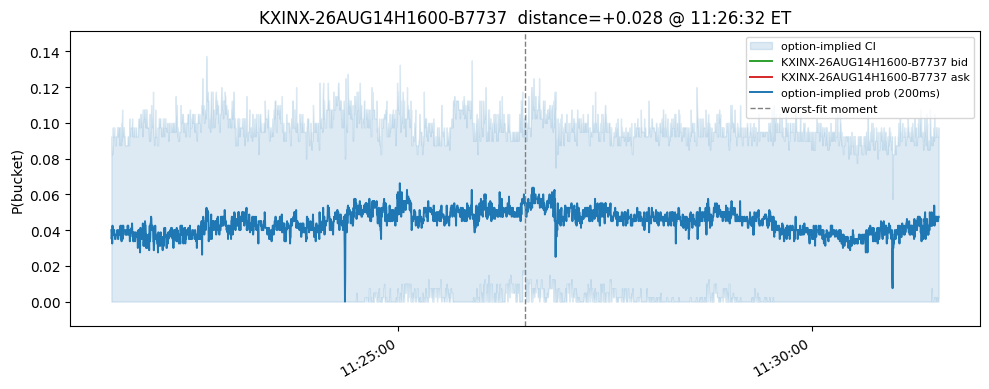

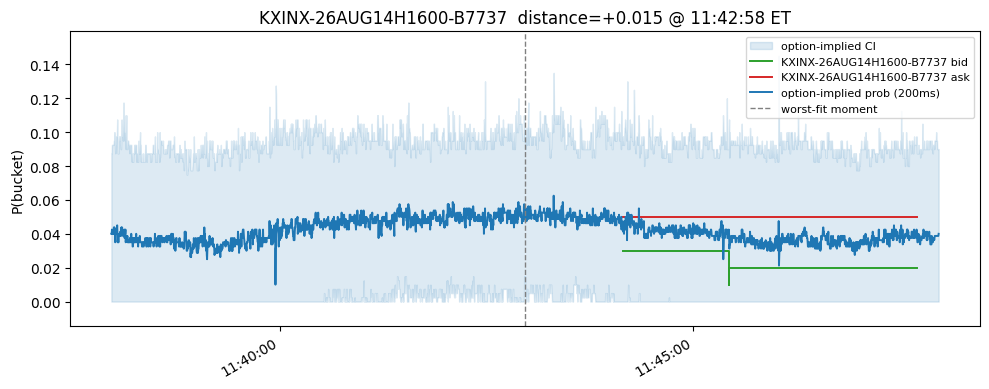

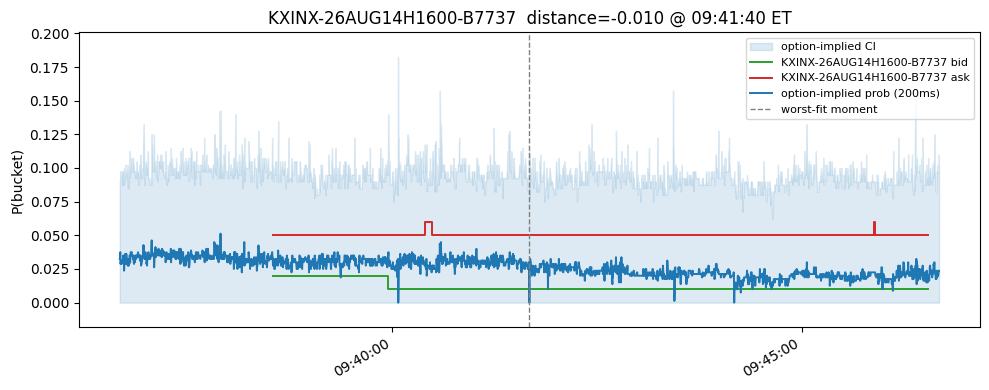

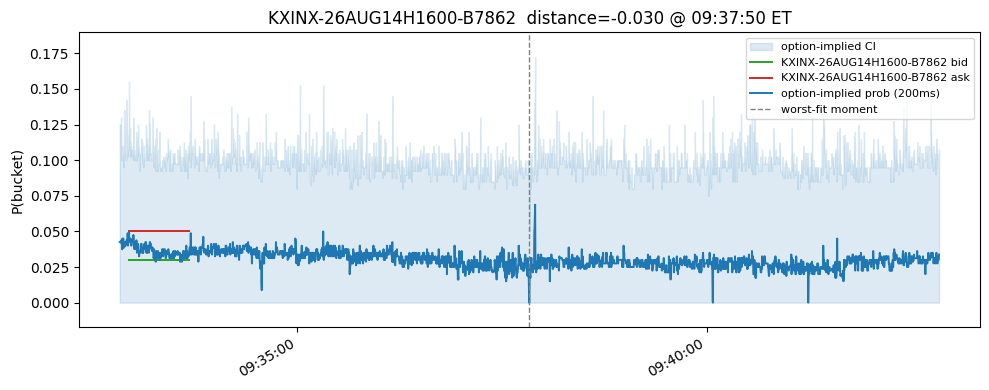

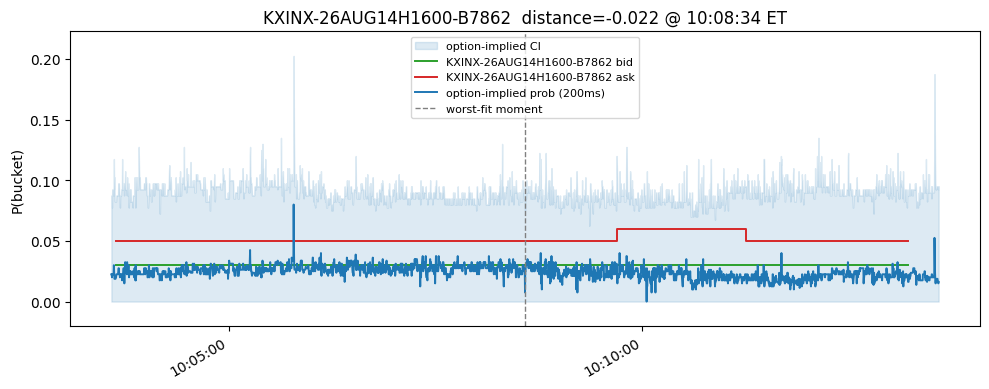

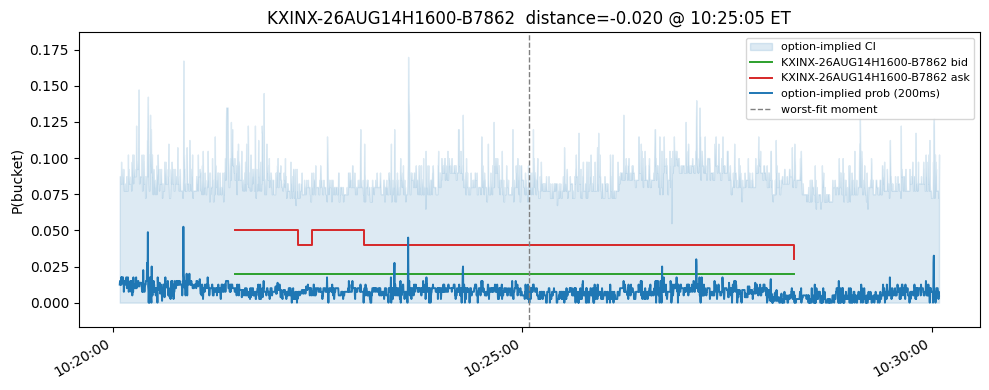

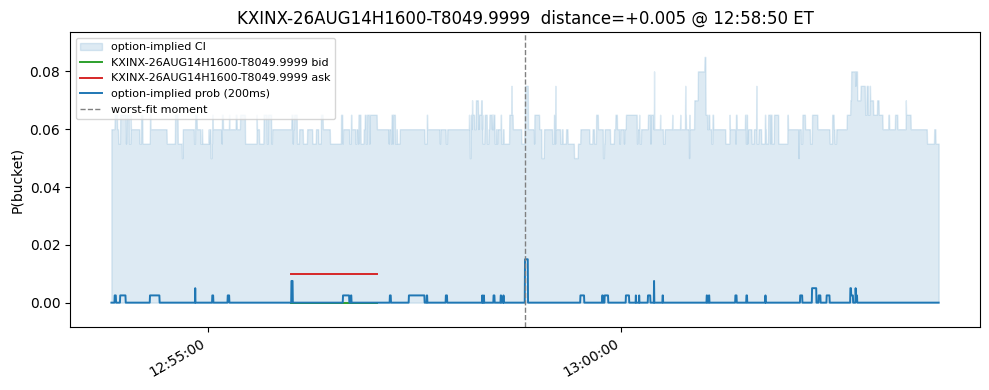

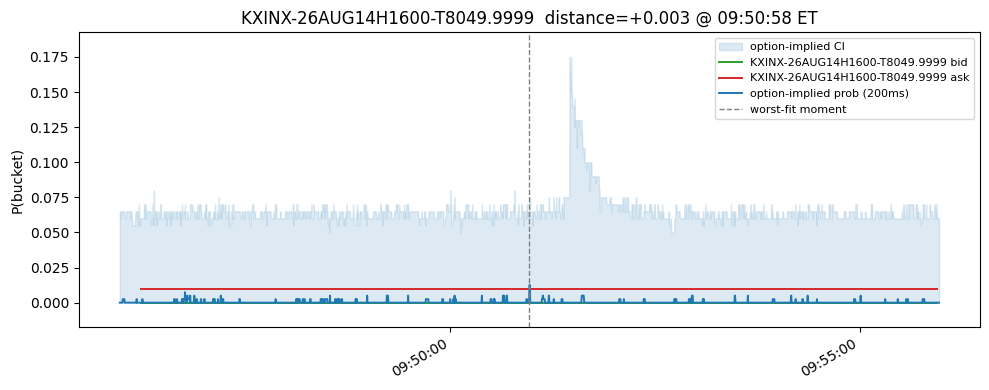

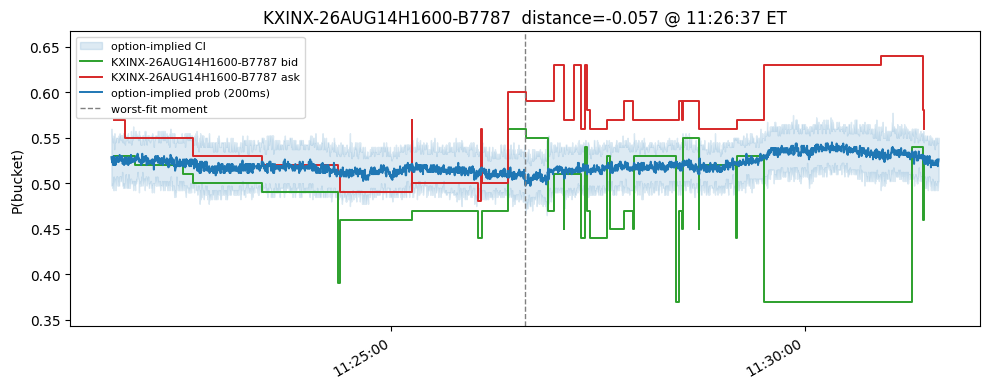

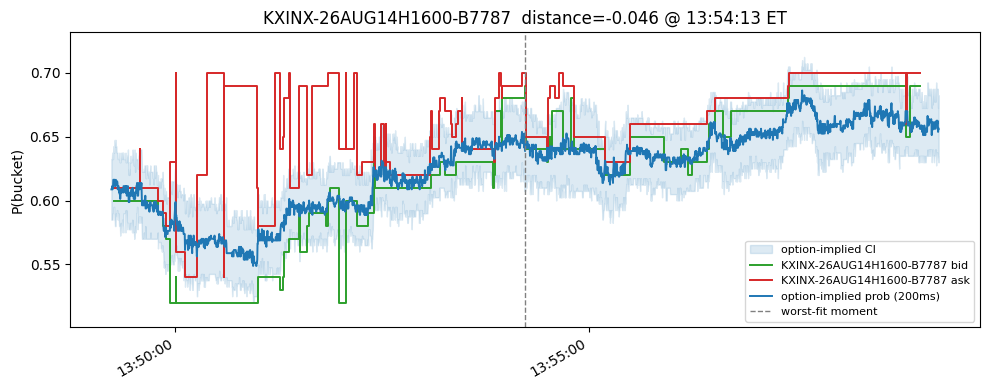

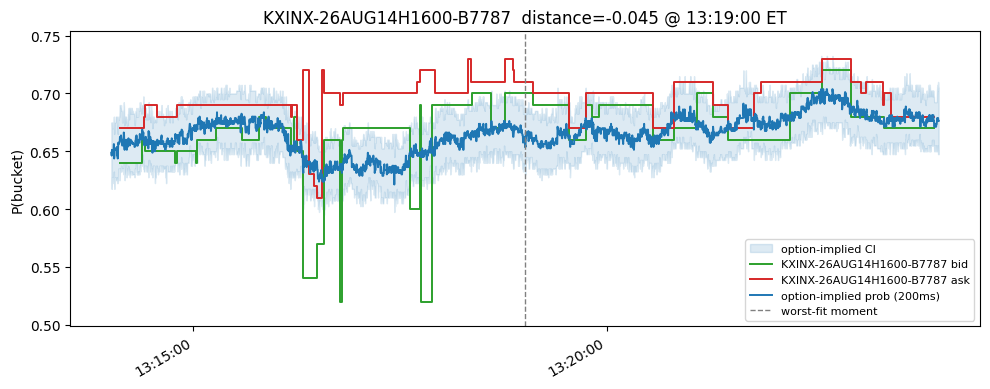

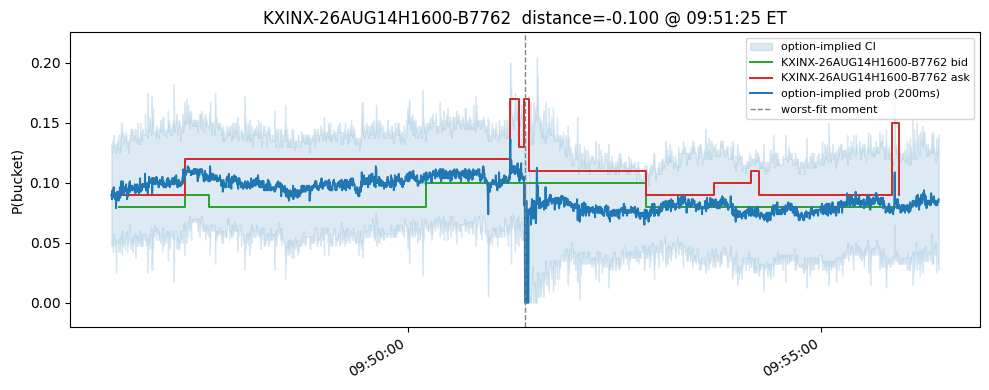

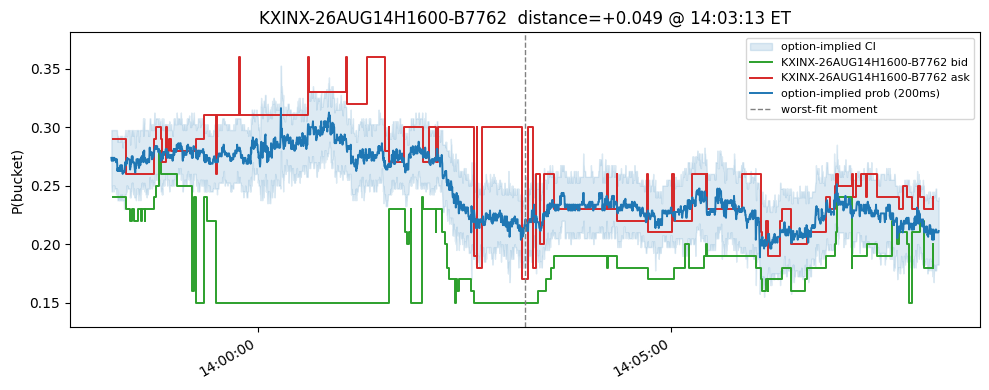

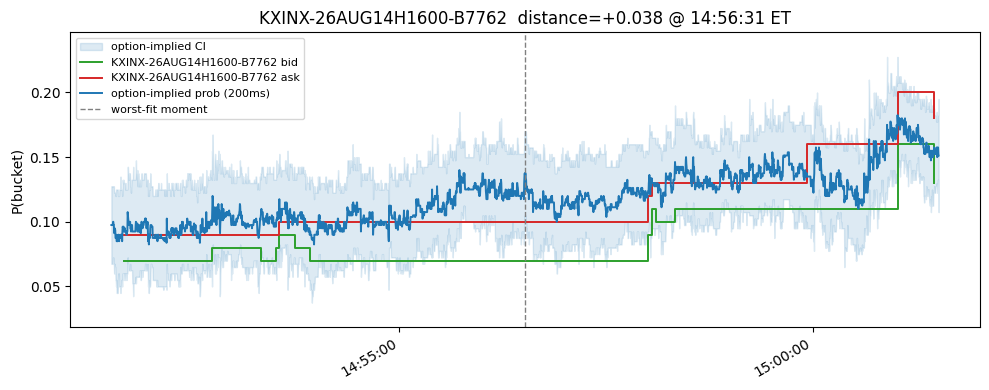

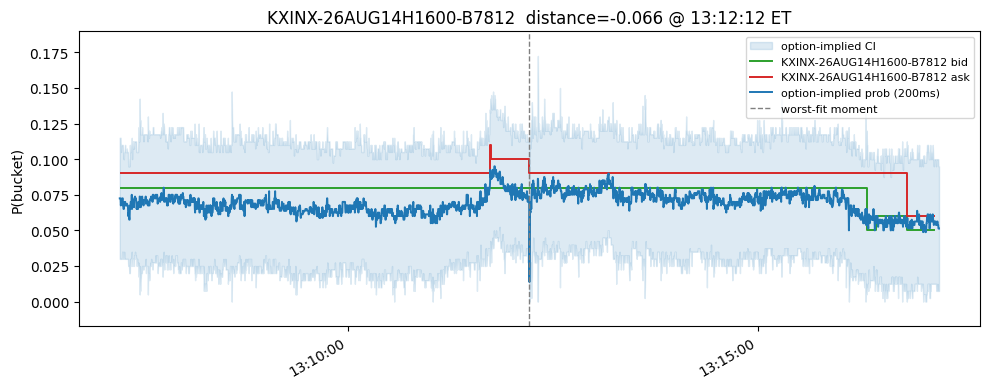

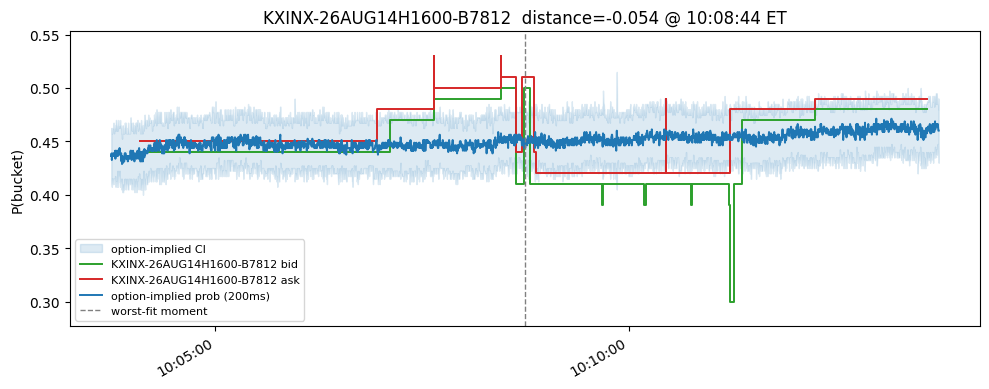

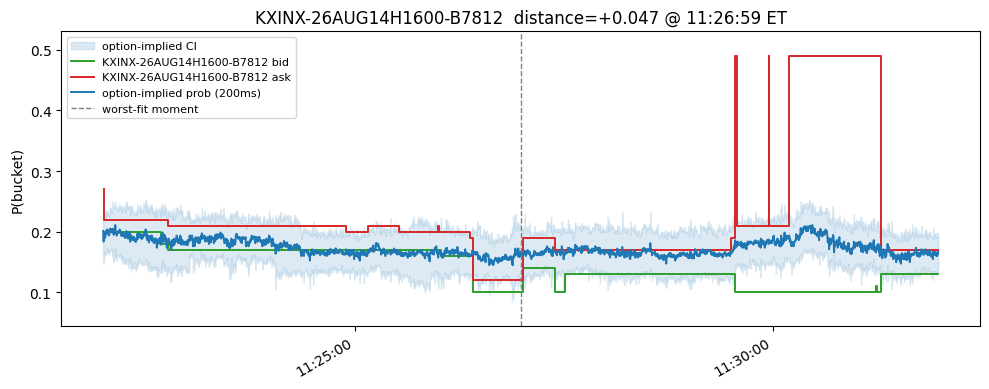

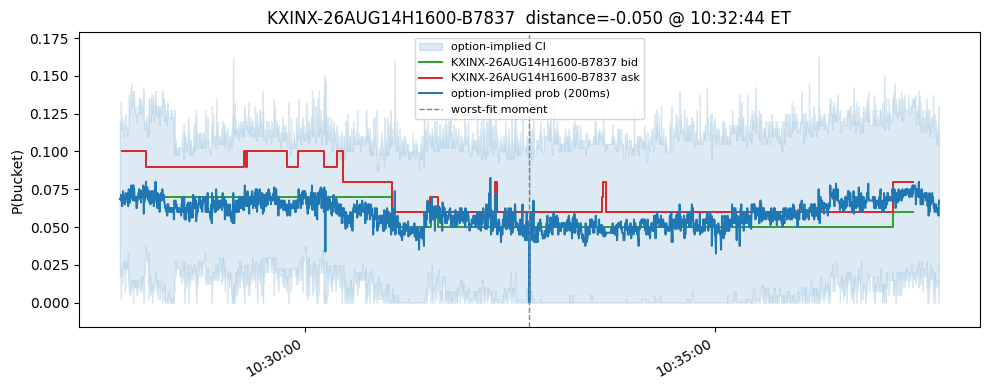

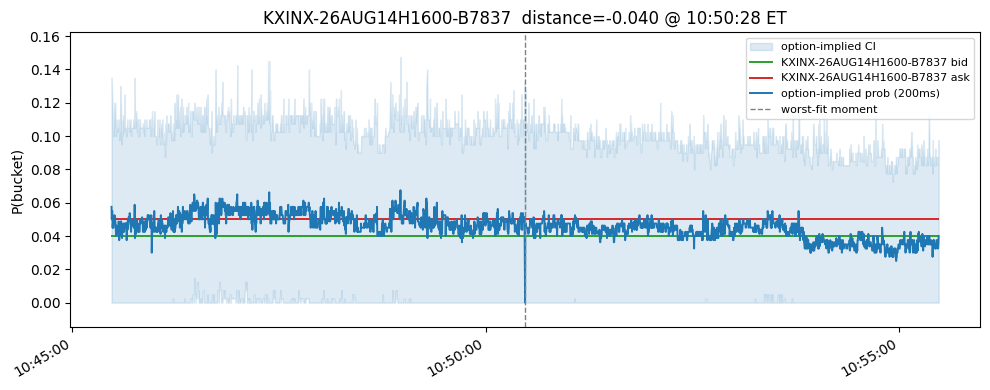

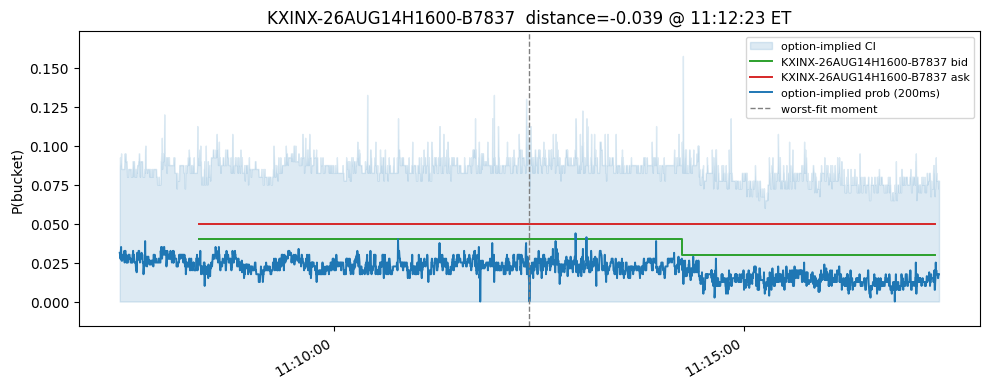

In [6]:
half_window = pd.Timedelta("5min")

for w in worst_fits:
    ticker = w["ticker"]
    kt = data["kalshi_ticks"][data["kalshi_ticks"]["ticker"] == ticker].sort_values("time")
    t0, t1 = w["time"] - half_window, w["time"] + half_window
    p_window = probs[ticker][(probs.index >= t0) & (probs.index <= t1)]
    p_lo_window = probs_lo[ticker][(probs_lo.index >= t0) & (probs_lo.index <= t1)]
    p_hi_window = probs_hi[ticker][(probs_hi.index >= t0) & (probs_hi.index <= t1)]
    kt_window = kt[(kt["time"] >= t0) & (kt["time"] <= t1)]

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.fill_between(p_window.index, p_lo_window, p_hi_window, color="tab:blue", alpha=0.15, label="option-implied CI")
    ax.step(kt_window["time"], kt_window["bid"], where="post", color="tab:green", lw=1.4, label=f"{ticker} bid")
    ax.step(kt_window["time"], kt_window["ask"], where="post", color="tab:red", lw=1.4, label=f"{ticker} ask")
    ax.plot(p_window.index, p_window.values, color="tab:blue", lw=1.4, label="option-implied prob (200ms)")
    ax.axvline(w["time"], color="gray", ls="--", lw=1, label="worst-fit moment")

    # Scale to the data actually in view, not a fixed [0, 1].
    visible = pd.concat([p_hi_window, p_lo_window, kt_window["bid"], kt_window["ask"]]).dropna()
    lo, hi = visible.min(), visible.max()
    pad = max((hi - lo) * 0.1, 0.005)
    ax.set_ylim(lo - pad, hi + pad)

    ax.set_title(f"{ticker}  distance={w['distance']:+.3f} @ {w['time'].tz_convert(laf.ET):%H:%M:%S} ET")
    ax.set_ylabel("P(bucket)")
    ax.legend(loc="best", fontsize=8)
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S", tz=laf.ET))
    fig.autofmt_xdate()
    plt.tight_layout()
    plt.show()
